<a href="https://colab.research.google.com/github/iam-asm/SmartSort/blob/main/model/train_mobilenetv2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [REPEAT]
# Cell 1: check TensorFlow and the GPU
import tensorflow as tf
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# [REPEAT]
# Cell 2: connect Google Drive, where datasets and models will live
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/SmartSort/data

Mounted at /content/drive


In [ ]:
# Cell 3: download the dataset (takes a minute or two)
import kagglehub
path = kagglehub.dataset_download('mostafaabla/garbage-classification')
print(path)

Using Colab cache for faster access to the 'garbage-classification' dataset.
/kaggle/input/garbage-classification


In [ ]:
# Cell 4: count the images in each folder
import os
for folder, subfolders, files in os.walk(path):
    if files:
        print(f"{len(files):6d}  {folder.replace(path, '')}")

   769  /garbage_classification/metal
   775  /garbage_classification/white-glass
   985  /garbage_classification/biological
  1050  /garbage_classification/paper
   607  /garbage_classification/brown-glass
   945  /garbage_classification/battery
   697  /garbage_classification/trash
   891  /garbage_classification/cardboard
  1977  /garbage_classification/shoes
  5325  /garbage_classification/clothes
   865  /garbage_classification/plastic
   629  /garbage_classification/green-glass


In [ ]:
# Cell 5
import os, random, shutil

SRC = os.path.join(path, 'garbage_classification')
DST = '/content/data/public'

# Folder names start with the bin number, so the model's class order = bin order
CLASS_MAP = {
    '1_Metal':       ['metal'],
    '2_Plastic':     ['plastic'],
    '3_Paper':       ['paper', 'cardboard'],
    '4_Organic':     ['biological'],
    '5_SpecialCare': ['battery'],
    '6_Glass':       ['brown-glass', 'green-glass', 'white-glass'],
    '7_Textile':     ['clothes', 'shoes'],
    '8_Other':       ['trash'],
}
MAX_PER_CLASS = 2000
random.seed(42)

shutil.rmtree(DST, ignore_errors=True)
for cls, folders in CLASS_MAP.items():
    files = []
    for f in folders:
        d = os.path.join(SRC, f)
        files += [os.path.join(d, n) for n in os.listdir(d)
                  if n.lower().endswith(('.jpg', '.jpeg', '.png'))]
    random.shuffle(files)
    files = files[:MAX_PER_CLASS]
    out = os.path.join(DST, cls)
    os.makedirs(out)
    for i, src in enumerate(files):
        ext = os.path.splitext(src)[1].lower()
        shutil.copy(src, os.path.join(out, f'{cls.lower()}_{i:04d}{ext}'))
    print(f'{cls:14s} {len(files)} images')

1_Metal        769 images
2_Plastic      865 images
3_Paper        1941 images
4_Organic      985 images
5_SpecialCare  945 images
6_Glass        2000 images
7_Textile      2000 images
8_Other        697 images


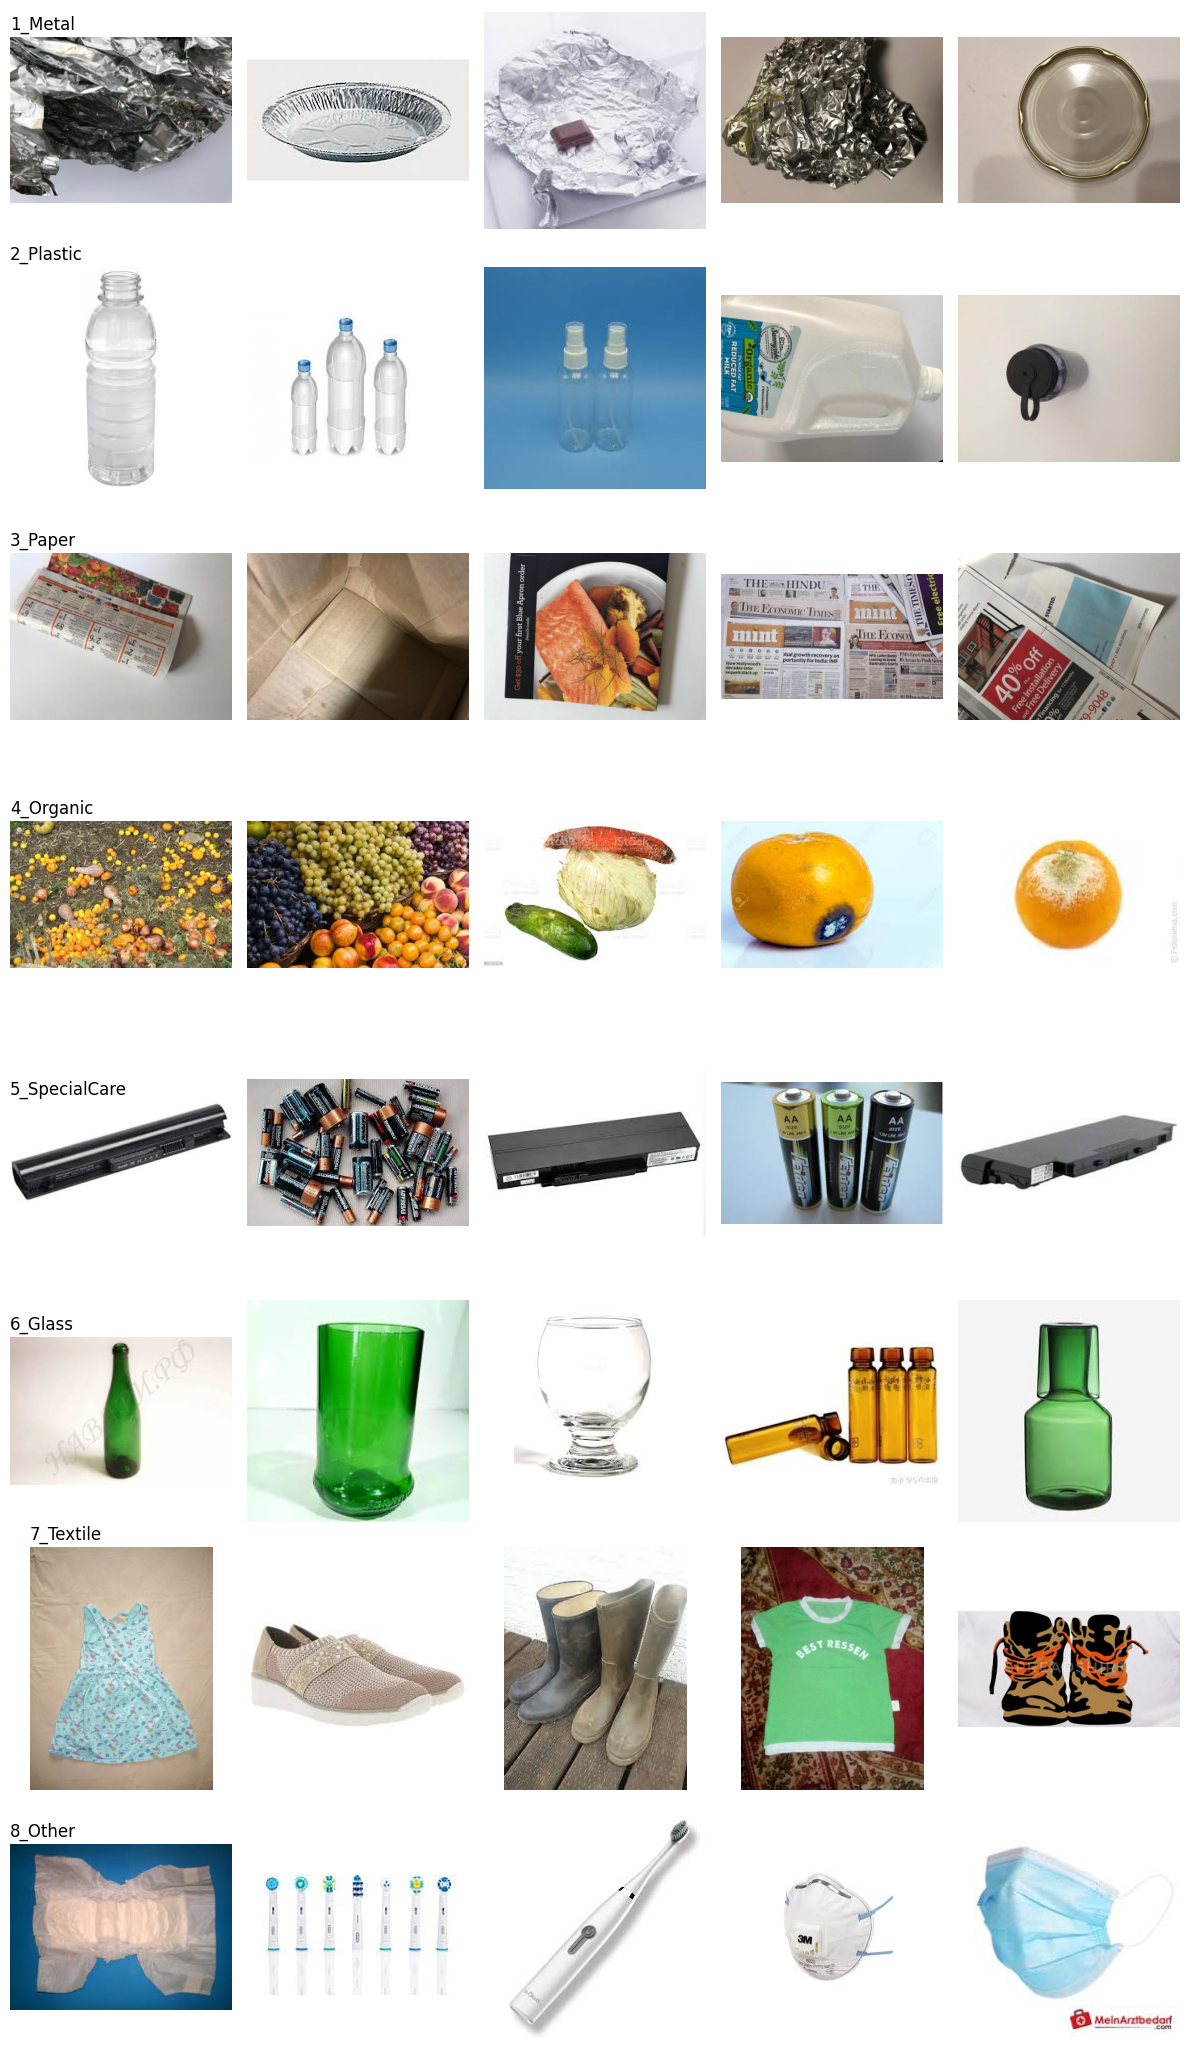

In [ ]:
# Cell 6
import matplotlib.pyplot as plt
from PIL import Image

classes = sorted(os.listdir(DST))
fig, axes = plt.subplots(len(classes), 5, figsize=(12, 2.6 * len(classes)))
for r, cls in enumerate(classes):
    for c, name in enumerate(random.sample(os.listdir(os.path.join(DST, cls)), 5)):
        ax = axes[r][c]
        ax.imshow(Image.open(os.path.join(DST, cls, name)))
        ax.axis('off')
        if c == 0:
            ax.set_title(cls, loc='left')
plt.tight_layout()
plt.show()

In [ ]:
# Cell 7
!mkdir -p /content/drive/MyDrive/SmartSort/data
!rm -f /content/drive/MyDrive/SmartSort/data/public_v0.zip
!cd /content/data && zip -qr /content/drive/MyDrive/SmartSort/data/public_v0.zip public
print('Saved to Drive')

Saved to Drive


In [3]:
# [REPEAT]
# Cell 8
!mkdir -p /content/data && cd /content/data && unzip -qo /content/drive/MyDrive/SmartSort/data/public_v0.zip
DST = '/content/data/public'
import os
print(sorted(os.listdir(DST)))

['1_Metal', '2_Plastic', '3_Paper', '4_Organic', '5_SpecialCare', '6_Glass', '7_Textile', '8_Other']


In [5]:
# [REPEAT]
# Cell 9: load images, split 70/15/15, class weights
import tensorflow as tf, numpy as np, os

IMG_SIZE = (224, 224)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds, temp_ds = tf.keras.utils.image_dataset_from_directory(
    DST, validation_split=0.3, subset='both', seed=42,
    image_size=IMG_SIZE, batch_size=BATCH)
class_names = train_ds.class_names
print(class_names)
train_ds = train_ds.prefetch(AUTOTUNE)

# Split the other 30% into validation and test by file, the same way every session
paths = sorted(temp_ds.file_paths)
np.random.default_rng(42).shuffle(paths)
half = len(paths) // 2

def make_ds(file_list):
    labels = [class_names.index(os.path.basename(os.path.dirname(p))) for p in file_list]
    ds = tf.data.Dataset.from_tensor_slices((file_list, labels))
    def load(path, label):
        img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        return tf.image.resize(img, IMG_SIZE), label
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).cache().prefetch(AUTOTUNE)

val_ds = make_ds(paths[:half])
test_ds = make_ds(paths[half:])
print(f'validation: {half} images, test: {len(paths) - half} images')

counts = np.array([len(os.listdir(os.path.join(DST, c))) for c in class_names])
class_weight = dict(enumerate(counts.sum() / (len(counts) * counts)))

Found 10202 files belonging to 8 classes.
Using 7142 files for training.
Using 3060 files for validation.
['1_Metal', '2_Plastic', '3_Paper', '4_Organic', '5_SpecialCare', '6_Glass', '7_Textile', '8_Other']
validation: 1530 images, test: 1530 images


In [ ]:
# Cell 10
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical'),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.2),
])

base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                         include_top=False, weights='imagenet')
base.trainable = False   # stage 1: keep the pretrained part frozen

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = tf.keras.layers.Rescaling(1/127.5, offset=-1)(x)   # pixels 0–255 → -1 to 1, as MobileNetV2 expects
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Cell 11
callbacks = [tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)]
history = model.fit(train_ds, validation_data=val_ds, epochs=10,
                    class_weight=class_weight, callbacks=callbacks)

Epoch 1/10
 51/224 ━━━━━━━━━━━━━━━━━━━━ 5:32 2s/step - accuracy: 0.3322 - loss: 1.9212

KeyboardInterrupt: 

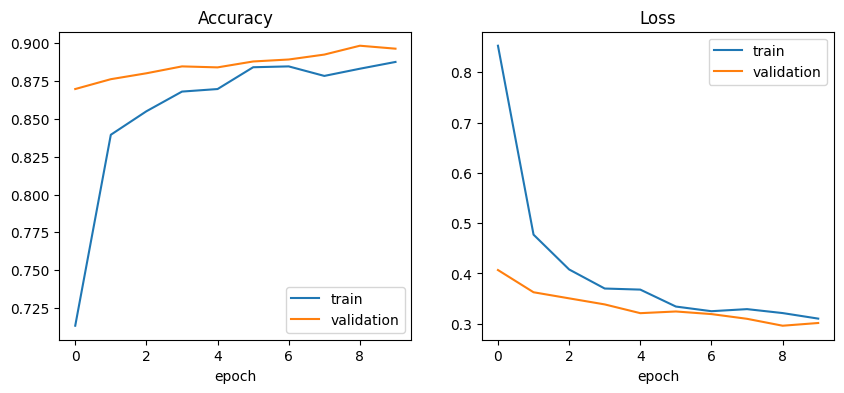

In [ ]:
# Cell 12
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.show()

In [ ]:
# Cell 13
# Cell 13: save the model to Drive
os.makedirs('/content/drive/MyDrive/SmartSort/models', exist_ok=True)
model.save('/content/drive/MyDrive/SmartSort/models/stage1.keras')
print('Model saved')

Model saved


In [6]:
# Cell 14: load stage 1 from Drive
MODELS = '/content/drive/MyDrive/SmartSort/models'
model = tf.keras.models.load_model(f'{MODELS}/stage1.keras')
loss, acc = model.evaluate(val_ds, verbose=0)
print(f'Stage 1 validation accuracy: {acc:.3f}')

Stage 1 validation accuracy: 0.886


In [7]:
# Cell 15: prepare fine-tuning
base = next(l for l in model.layers if l.name.startswith('mobilenetv2'))
base.trainable = True
FINE_TUNE_AT = 100                      # keep layers 0–99 frozen
for layer in base.layers[:FINE_TUNE_AT]:
    layer.trainable = False
print(f'MobileNetV2 layers: {len(base.layers)}, now trainable: {sum(l.trainable for l in base.layers)}')

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),   # 100x smaller than stage 1
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

MobileNetV2 layers: 154, now trainable: 54


In [8]:
# Cell 16: train stage 2 (fine-tuning)
callbacks = [tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)]
history_ft = model.fit(train_ds, validation_data=val_ds, epochs=10,
                       class_weight=class_weight, callbacks=callbacks)

Epoch 1/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 46s 125ms/step - accuracy: 0.7984 - loss: 0.5891 - val_accuracy: 0.8980 - val_loss: 0.2989
Epoch 2/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 25s 112ms/step - accuracy: 0.8430 - loss: 0.4492 - val_accuracy: 0.9013 - val_loss: 0.3027
Epoch 3/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 25s 113ms/step - accuracy: 0.8601 - loss: 0.3972 - val_accuracy: 0.9013 - val_loss: 0.2943
Epoch 4/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 25s 113ms/step - accuracy: 0.8731 - loss: 0.3570 - val_accuracy: 0.8974 - val_loss: 0.2870
Epoch 5/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 25s 112ms/step - accuracy: 0.8818 - loss: 0.3227 - val_accuracy: 0.8974 - val_loss: 0.2896
Epoch 6/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 25s 112ms/step - accuracy: 0.8912 - loss: 0.3147 - val_accuracy: 0.8954 - val_loss: 0.2888
Epoch 7/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 25s 112ms/step - accuracy: 0.8888 - loss: 0.3016 - val_accuracy: 0.9013 - val_loss: 0.2805
Epoch 8/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 26s 114ms/step - accuracy: 0.8986 - loss: 0

In [9]:
# Cell 17: save the fine-tuned model
model.save(f'{MODELS}/stage2_finetuned.keras')
print('Fine-tuned model saved')

Fine-tuned model saved


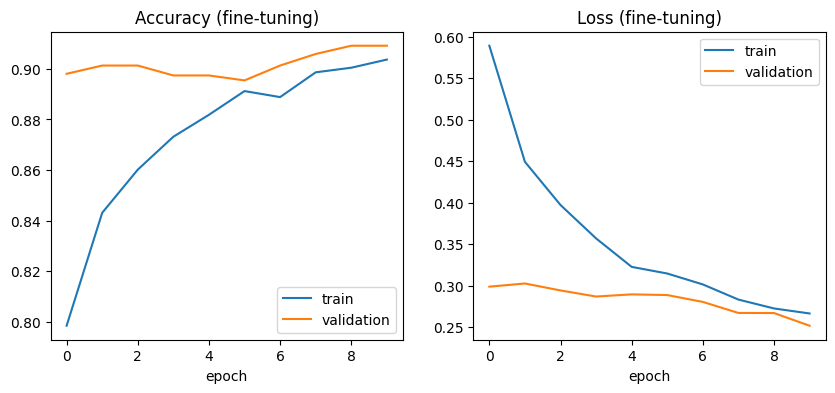

In [10]:
# Cell 18: fine-tuning curves
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history_ft.history['accuracy'], label='train')
plt.plot(history_ft.history['val_accuracy'], label='validation')
plt.title('Accuracy (fine-tuning)'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_ft.history['loss'], label='train')
plt.plot(history_ft.history['val_loss'], label='validation')
plt.title('Loss (fine-tuning)'); plt.xlabel('epoch'); plt.legend()
plt.show()

               precision    recall  f1-score   support

      1_Metal      0.782     0.907     0.840       107
    2_Plastic      0.836     0.842     0.839       133
      3_Paper      0.971     0.908     0.938       294
    4_Organic      0.906     0.993     0.947       136
5_SpecialCare      0.970     0.975     0.972       163
      6_Glass      0.959     0.885     0.921       288
    7_Textile      0.980     0.970     0.975       302
      8_Other      0.874     0.972     0.920       107

     accuracy                          0.929      1530
    macro avg      0.910     0.932     0.919      1530
 weighted avg      0.933     0.929     0.930      1530



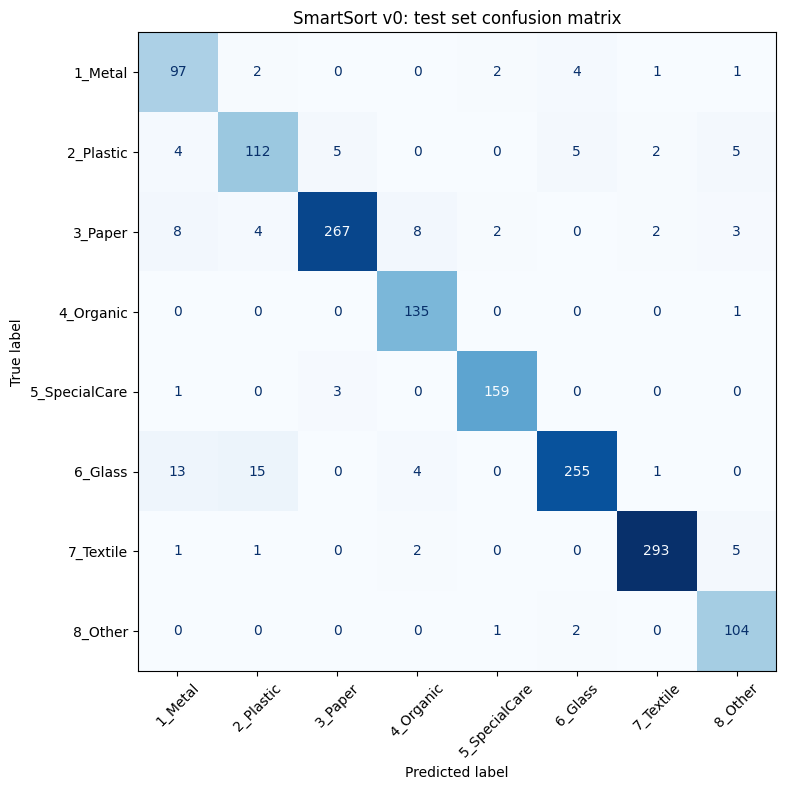

In [11]:
# Cell 19: test set results
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true, y_pred = [], []
for images, labels in test_ds:
    y_true += list(labels.numpy())
    y_pred += list(model.predict(images, verbose=0).argmax(axis=1))

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
plt.title('SmartSort v0: test set confusion matrix')
plt.tight_layout()
plt.savefig(f'{MODELS}/confusion_matrix_v0.png', dpi=150)
plt.show()

In [12]:
# Cell 20: export to TFLite
MODELS = '/content/drive/MyDrive/SmartSort/models'
model = tf.keras.models.load_model(f'{MODELS}/stage2_finetuned.keras')

# Inference model: same layers, but without the random augmentation (only needed for training)
inp = tf.keras.Input(shape=IMG_SIZE + (3,))
x = inp
for layer in model.layers[1:]:
    if isinstance(layer, tf.keras.Sequential):   # skip the augmentation block
        continue
    x = layer(x)
infer_model = tf.keras.Model(inp, x)
infer_model.export('/content/saved_v0')

converter = tf.lite.TFLiteConverter.from_saved_model('/content/saved_v0')
tflite_float = converter.convert()

converter = tf.lite.TFLiteConverter.from_saved_model('/content/saved_v0')
converter.optimizations = [tf.lite.Optimize.DEFAULT]   # smaller, faster version
tflite_quant = converter.convert()

open(f'{MODELS}/smartsort_v0_float.tflite', 'wb').write(tflite_float)
open(f'{MODELS}/smartsort_v0_quant.tflite', 'wb').write(tflite_quant)
with open(f'{MODELS}/labels.txt', 'w') as f:
    f.write('\n'.join(class_names))

print(f'float: {len(tflite_float)/1e6:.1f} MB, quantised: {len(tflite_quant)/1e6:.1f} MB')

Saved artifact at '/content/saved_v0'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_676')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  138440155704848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138440155704080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138440155704272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138440155702736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138440155706192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138440155704656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138440155701968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138440155702160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138440155700624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138440155708304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138440155

In [14]:
# Cell 21: quantised TFLite accuracy on the test set
interp = tf.lite.Interpreter(model_content=tflite_quant)
interp.allocate_tensors()
inp_d = interp.get_input_details()[0]
out_d = interp.get_output_details()[0]

correct = total = 0
for images, labels in test_ds:
    for img, label in zip(images.numpy(), labels.numpy()):
        interp.set_tensor(inp_d['index'], img[None].astype('float32'))
        interp.invoke()
        correct += int(interp.get_tensor(out_d['index']).argmax() == label)
        total += 1
print(f'Quantised TFLite test accuracy: {correct/total:.3f}  (Keras model: 0.929)')

Quantised TFLite test accuracy: 0.931  (Keras model: 0.929)
